# CSC_51054_EP - Deep Learning
## Lab 7: Deep Visual Representation Learning

### Introduction

Two images of the same object category can look very different because of changes in colour, viewpoint, lighting, or background.  In this lab, we see how visual representations help us identify useful similarities between images.

#### *What is Visual Representation?*

In computer vision, a **visual representation** refers to the transformation of raw image pixels into a structured and informative format that a machine learning model can use to understand and reason about visual content.

Rather than operating directly on pixel intensities, modern vision systems extract **representations**, which are typically compact and often high-dimensional vectors, that encode semantic, structural, or spatial information about the input visual data (e.g., images or videos).

#### *Why is Visual Representation Important?*

- **Foundation of most CV tasks**: Classification, detection, segmentation, retrieval, and even image generation all rely on strong underlying representations.
- **Bridge between perception and decision**: A good visual representation helps models understand "what is in the image" and "how it relates to other images."
- **Transferability**: Powerful representations trained on large datasets (like ImageNet) can be reused for many downstream tasks with minimal fine-tuning.
- **Modularity and Generalisation**: Representations allow decoupling feature extraction from task-specific heads.

### Lab Overview and Setup

In this lab, we will explore several approaches to visual representation learning, ranging from traditional handcrafted features to learned CNN features and pretrained transformer representations.

#### Lab Structure

1. **Classic Feature Engineering**: Understand how HOG (Histogram of Oriented Gradients) [[CVPR'05]](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf) describes local image structure and use its features for classification. (Fun fact: HOG is from Inria!)
2. **Learning Visual Representations**: Train a simple CNN on [CIFAR-100](https://www.cs.toronto.edu/~kriz/cifar.html) and extract its learned features.
3. **Vision Transformers and Pretrained Representations**: Explain how a Vision Transformer (ViT) processes image patches, then use a pretrained DINO-ViT [[ICCV'21]](https://arxiv.org/abs/2104.14294) as a feature extractor.
4. **Comparing Representations**: Use t-SNE to visualise and compare the representations learned from each method.
5. **Discussion**: Discuss open challenges in deep visual representation learning.

#### Dataset: [CIFAR-100](https://www.cs.toronto.edu/~kriz/cifar.html)
- 100 object categories
- 32x32 colour images
- 150 images per class (100 training and 50 test), sampled from the original CIFAR-100 splits
- Diverse classes ranging from animals to vehicles

Place the provided `cifar100_balanced_100_50.npz` file in the same folder as this notebook. It contains 10,000 training images and 5,000 test images. The archive also includes `dino_features_cifar100_subset.npz`, containing precomputed DINO features for these same images.

#### Downstream Task: Image Classification
We will use extracted features for:
- Linear classification (Logistic Regression or a linear layer)
- Nearest-neighbour retrieval to inspect which images have similar representations
- t-SNE for visual inspection of representation quality


In [ ]:
# !pip install timm -q
# !pip install scikit-image -q


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
# Standard libraries
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import timm

# Image processing (for classic features)
from skimage.feature import hog
from skimage.color import rgb2gray

# Set the device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(device)

mps


In [3]:
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


class CIFAR100Subset(Dataset):
    def __init__(self, images, labels, transform):
        self.data = images
        self.targets = labels.tolist()
        self.transform = transform

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        image = Image.fromarray(self.data[index])
        return self.transform(image), self.targets[index]


data_file = Path("cifar100_balanced_100_50.npz")
if not data_file.is_file():
    raise FileNotFoundError(f"Place the provided {data_file.name} file beside the notebook.")

with np.load(data_file, allow_pickle=False) as data:
    train_images, train_labels = data["train_images"], data["train_labels"]
    test_images, test_labels = data["test_images"], data["test_labels"]
    class_names = data["classes"].tolist()

# For HOG and the CNN, use the original 32x32 images
base_transform = transforms.ToTensor()
train_dataset = CIFAR100Subset(train_images, train_labels, base_transform)
test_dataset = CIFAR100Subset(test_images, test_labels, base_transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(
    f"{len(class_names)} classes, {len(train_dataset):,} training images, {len(test_dataset):,} test images"
)


100 classes, 10,000 training images, 5,000 test images


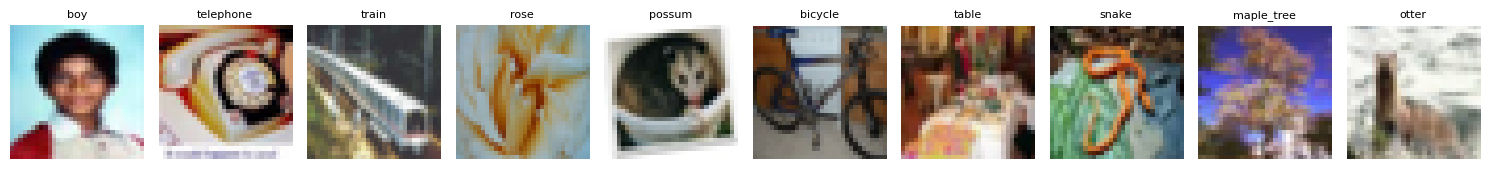

In [4]:
# Show a few examples of CIFAR-100
def show_cifar_samples(dataset, class_names, num_images=10):
    """Display a few sample images from the CIFAR-100 dataset."""
    plt.figure(figsize=(15, 2))
    for i in range(num_images):
        img, label = dataset[i]
        img = img.permute(1, 2, 0).numpy()  # CHW to HWC for plotting
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.title(class_names[label], fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


show_cifar_samples(train_dataset, class_names, num_images=10)

### 1. Classic Image Descriptors as Visual Representations (e.g. HOG)

#### 1.1 How HOG constructs a descriptor

**HOG (Histogram of Oriented Gradients)** is a classic feature descriptor used in traditional computer vision before the rise of deep learning. It was introduced by Dalal and Triggs in their 2005 [CVPR paper](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf) for pedestrian detection.

HOG describes an image through the **distribution of local intensity changes**. These changes reveal edges, contours, and texture. Unlike a CNN, HOG has no learned parameters. We use it to compute feature vectors from the images, then train a classifier on those vectors.

The equations below describe the **greyscale scikit-image implementation used in this lab**.

**Image gradients**

We first convert each RGB image to greyscale. We denote its intensity at column $x$ and row $y$ by $I(x,y)$. Away from the borders, horizontal and vertical differences are:

$$
g_x(x,y)=I(x+1,y)-I(x-1,y),\qquad
g_y(x,y)=I(x,y+1)-I(x,y-1).
$$

At the first and last columns, $g_x=0$, and at the first and last rows, $g_y=0$.

The gradient points from the darker side to the brighter side, perpendicular to the edge. Its **magnitude** measures how strong the change is at pixel $(x,y)$.

$$
m(x,y)=\sqrt{g_x(x,y)^2+g_y(x,y)^2}.
$$

We measure the gradient **orientation** clockwise from the right because image rows increase downwards. We use unsigned orientations in $[0,180^\circ)$, so opposite gradient directions contribute to the same bin.

$$
\theta(x,y)=
\begin{cases}
\left(\dfrac{180}{\pi}\arctan\!\left(\dfrac{g_y(x,y)}{g_x(x,y)}\right)\right)\bmod 180^\circ
& \text{if } g_x(x,y)\ne 0,\\[6pt]
90^\circ & \text{if } g_x(x,y)=0 \text{ and } g_y(x,y)\ne 0,\\
0^\circ & \text{if } g_x(x,y)=g_y(x,y)=0.
\end{cases}
$$

A zero gradient has zero magnitude, so its assigned angle contributes nothing to the histogram.

**Cell orientation histograms**

We divide the image into non-overlapping **cells**. We use **9 orientation bins**, each spanning $20^\circ$: $B_k=[20k^\circ,20(k+1)^\circ)$ for $k=0,\ldots,8$. Each pixel votes with its magnitude into the single bin containing its orientation. For a cell $C$, the implementation computes:

$$
h_C(k)=\frac{1}{|C|}\sum_{(x,y)\in C}
m(x,y)\,\mathbf{1}\{\theta(x,y)\in B_k\}.
$$

Here $|C|$ is the number of pixels in the cell, and $\mathbf{1}\{\cdot\}$ is the indicator function. The result is a magnitude-weighted sum divided by the cell area.

A histogram retains the dominant orientations in a cell but discards their exact pixel positions. Keeping separate histograms for separate cells preserves a coarse spatial layout.

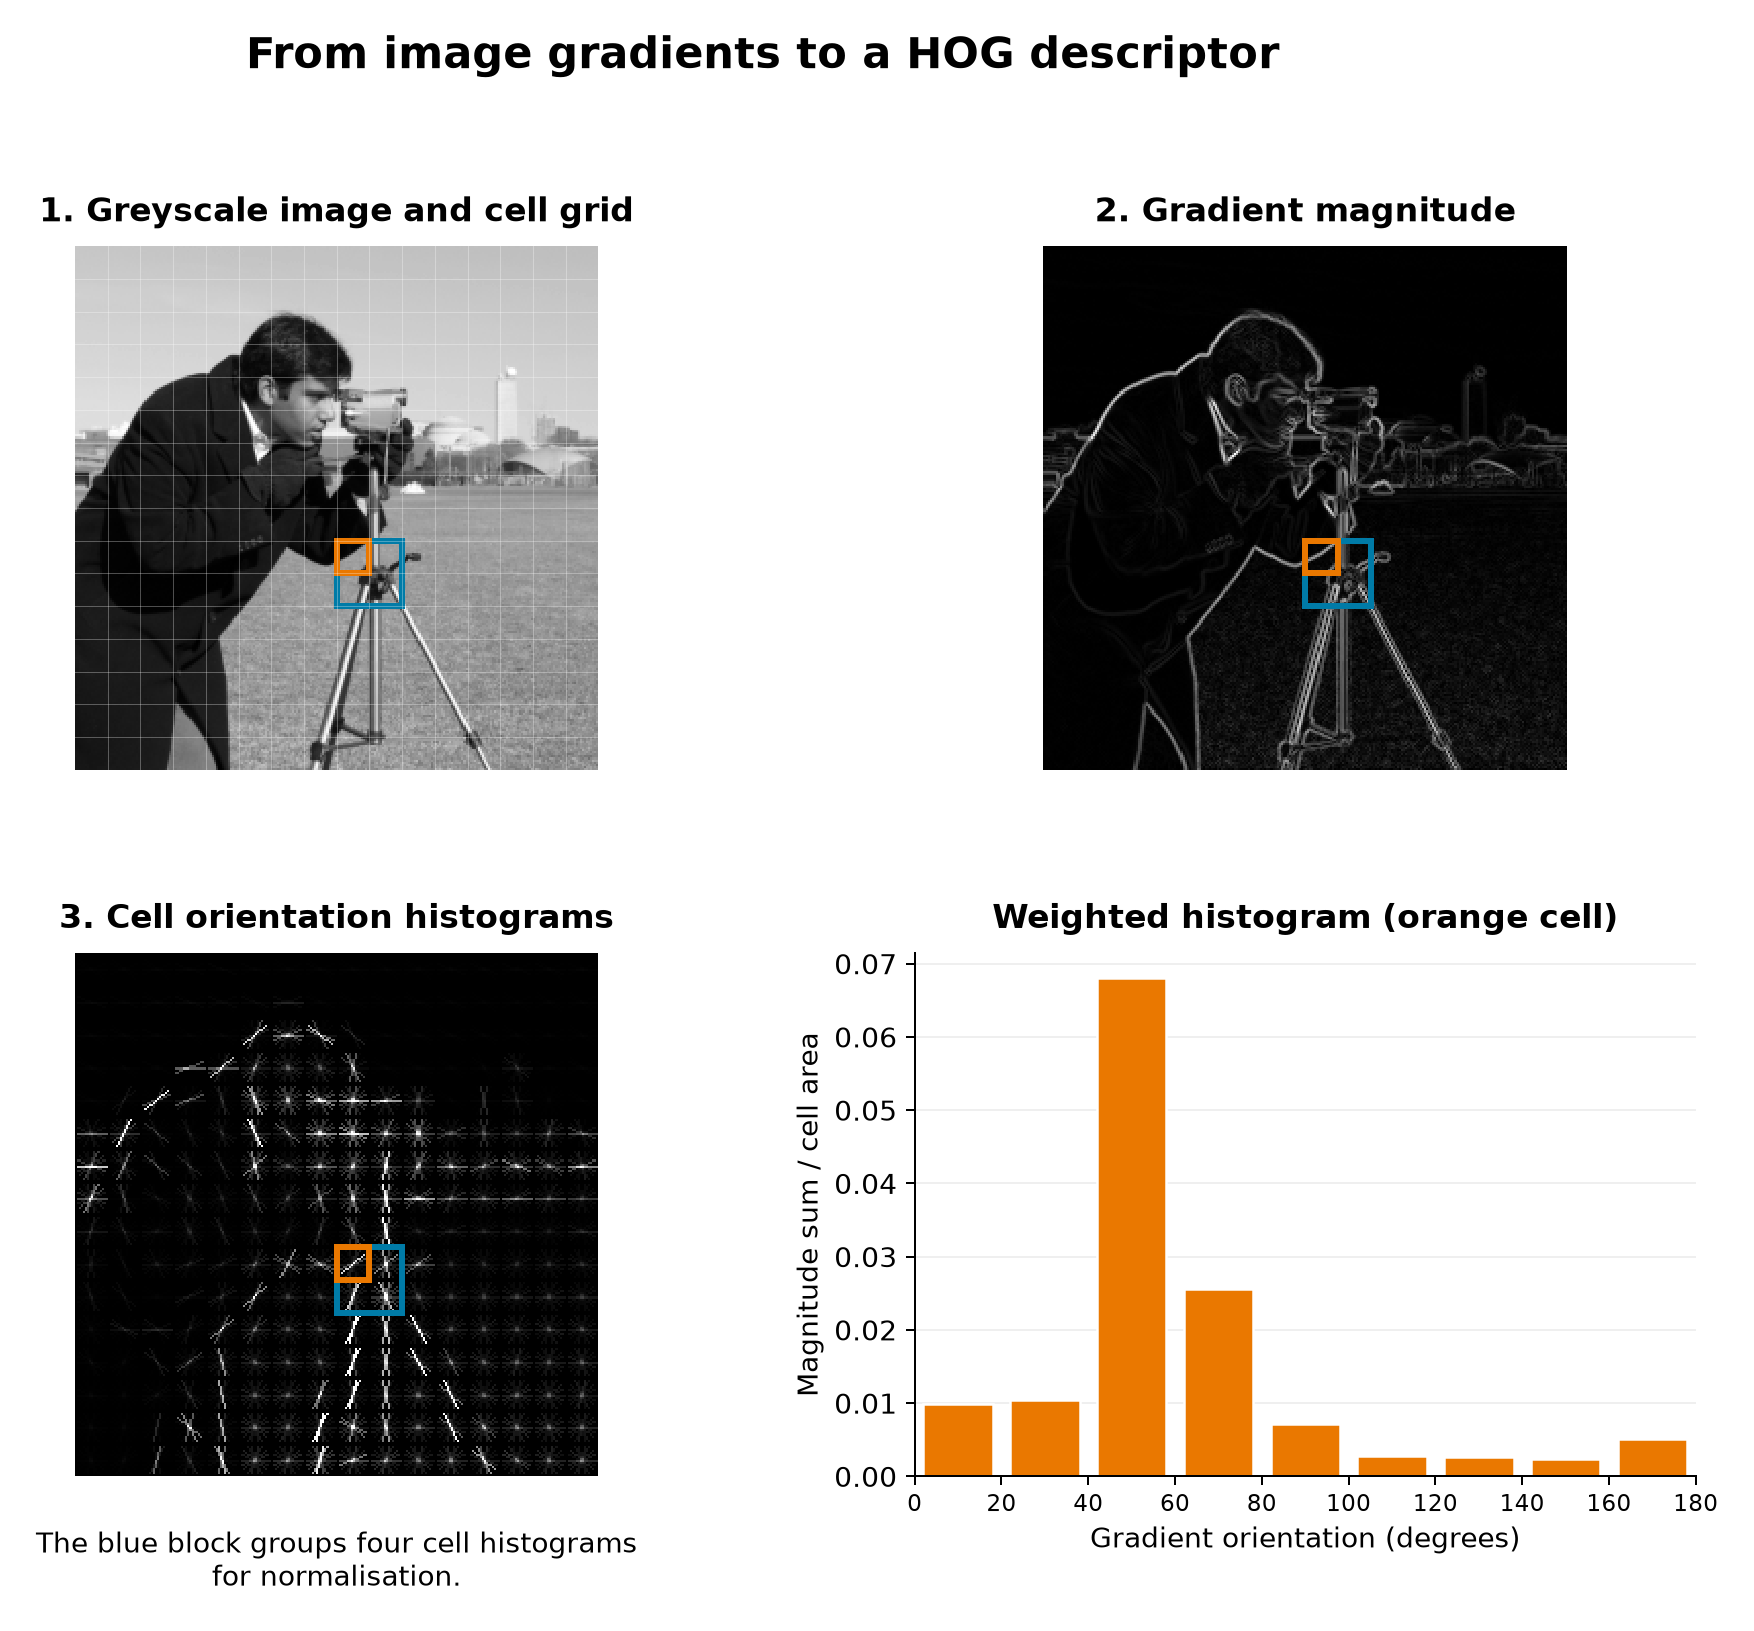

*The figure illustrates how HOG builds local orientation histograms. Orange marks one 16x16 cell and blue marks a 2x2-cell block. The histogram shows the magnitude-weighted votes divided by the orange cell's area, matching the function. In the HOG visualisation, short lines follow edge directions (perpendicular to the gradient-bin directions), while brighter lines indicate larger histogram values. These lines represent cell histograms before block normalisation, not the final feature vector. Image: `skimage.data.camera()`.*

<br>

**Block normalisation**

Changing image contrast can multiply gradient magnitudes without changing the underlying shape. We concatenate the histograms of a **2x2-cell block** into a vector $v$. The code uses **L2-Hys** normalisation, with these three operations:

$$
u=\frac{v}{\sqrt{\lVert v\rVert_2^2+\varepsilon^2}},\qquad
w_i=\min(u_i,0.2),\qquad
\widehat v=\frac{w}{\sqrt{\lVert w\rVert_2^2+\varepsilon^2}}.
$$

The function first normalises, then clips large entries, then normalises again. It uses $\varepsilon=10^{-5}$ to prevent division by zero. This reduces sensitivity to contrast changes while limiting the influence of very strong gradients. Each block is normalised separately.

**The final descriptor**

We slide the block by one cell at a time and concatenate the resulting normalised vectors. Blocks overlap, so a cell can contribute under several local normalisations.

For our **32x32 CIFAR-100 images**, `pixels_per_cell=(4, 4)` gives an 8x8 cell grid. With `cells_per_block=(2, 2)`, there are 7x7 overlapping blocks. Each block contains $2\times2\times9=36$ values, giving:

$$
\text{descriptor length}=7\times7\times36=1764.
$$

We now have one fixed-length vector per image. It captures local shape and texture, but our greyscale conversion discards colour, and HOG does not learn which patterns distinguish the object categories.


#### 1.2 Constructing one cell's histogram

The provided code below prepares the gradient magnitudes and orientations for the **same orange 16x16 cell shown in the figure**. We use a larger image here to make the construction visible; the CIFAR-100 extraction below uses 4x4 cells.


In [8]:
# Gradients for the orange cell in the figure above
from skimage import data
from skimage.transform import resize

hog_example = resize(data.camera(), (256, 256), anti_aliasing=True)
example_gx = np.zeros_like(hog_example)
example_gy = np.zeros_like(hog_example)
example_gx[:, 1:-1] = hog_example[:, 2:] - hog_example[:, :-2]
example_gy[1:-1, :] = hog_example[2:, :] - hog_example[:-2, :]
example_magnitudes = np.hypot(example_gx, example_gy)
example_orientations = np.rad2deg(np.arctan2(example_gy, example_gx)) % 180

# The highlighted cell occupies rows 144:160 and columns 128:144
cell_magnitudes = example_magnitudes[144:160, 128:144] # this give 16 rows
cell_orientations = example_orientations[144:160, 128:144] # 16 as well so the size is 16*16 for the next calculation
bin_edges = np.arange(0, 181, 20)

> **Task 1**: Compute the orange cell's orientation histogram using `np.histogram`. Flatten `cell_orientations` and `cell_magnitudes` with `.ravel()`, use the provided `bin_edges`, and weight each vote by its gradient magnitude. Divide the weighted sums by the number of pixels in the cell, then compare the provided plot with **Weighted histogram (orange cell)** in the figure above.


Cell histogram: [0.009946 0.010371 0.068068 0.025586 0.007159 0.002777 0.002695 0.00235
 0.005057]


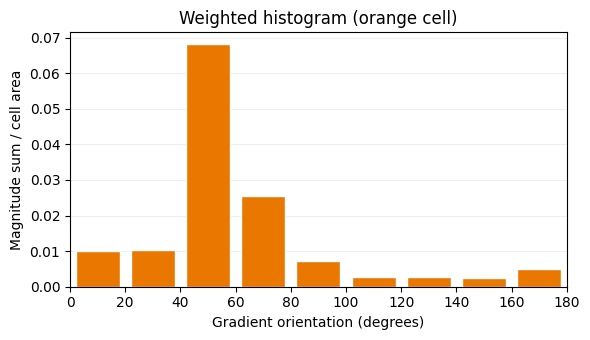

In [7]:
# > YOUR CODE HERE: accumulate magnitude-weighted votes
weighted_sums, _ = np.histogram(cell_orientations, bins=bin_edges, weights=cell_magnitudes)

# > YOUR CODE HERE: divide by the cell area
cell_histogram = weighted_sums/(16*16)

print("Cell histogram:", np.round(cell_histogram, 6))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(
    (bin_edges[:-1] + bin_edges[1:]) / 2,
    cell_histogram,
    width=16,
    color="#ea7800",
    edgecolor="white",
)
ax.set(
    xlim=(0, 180),
    xlabel="Gradient orientation (degrees)",
    ylabel="Magnitude sum / cell area",
    title="Weighted histogram (orange cell)",
)
ax.set_xticks(bin_edges)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

**Questions:**

1. Which orientation interval receives the largest contribution?
2. If we rearrange the pixels within this cell, keeping each magnitude paired with its orientation, does its histogram change? What information does the histogram discard?


1. From the graph, we can see that the interval from orientation [40,60] has the largest contribution.
2. The histogram will not be changing since the each pixel would still add its own maginitude to the bins with it own orientaton. Also the final answer is just the sum over all the pixels without any order so the sum stays the unchanged. 

#### 1.3 Classifying images using HOG features

We now apply the same construction to the CIFAR-100 images and use the resulting vectors for classification.

The following code uses [`skimage.feature.hog`](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog) to perform these steps.


In [9]:
def extract_hog_features(dataset, pixels_per_cell=(4, 4), cells_per_block=(2, 2), visualize=False):
    """
    Extract HOG features from CIFAR-100 images (converting them to greyscale first).
    Returns: X (features), y (labels)
    """
    X, y = [], []

    for img, label in tqdm(dataset, desc="Extracting HOG features"):
        img_gray = rgb2gray(img.permute(1, 2, 0).numpy())  # Convert tensor to HWC then to greyscale
        hog_vec = hog(
            img_gray,
            orientations=9,
            pixels_per_cell=pixels_per_cell,
            cells_per_block=cells_per_block,
            block_norm="L2-Hys",
            transform_sqrt=False,
            visualize=visualize,
            feature_vector=True,
        )
        X.append(hog_vec)
        y.append(label)

    return np.array(X), np.array(y)


# Extract features from train and test sets
X_train_hog, y_train = extract_hog_features(train_dataset)
X_test_hog, y_test = extract_hog_features(test_dataset)
print("Check feature dims:", np.shape(X_train_hog), np.shape(X_test_hog))
print("Check labels:", np.shape(y_train))

Extracting HOG features: 100%|██████████| 5000/5000 [00:03<00:00, 1434.38it/s]

Check feature dims: (10000, 1764) (5000, 1764)
Check labels: (10000,)


We now train and evaluate a logistic regression classifier on the HOG feature vectors. The following cell creates this classifier (`clf_lr`).

> **Task 2**: Fit `clf_lr` on the training HOG features and labels. Predict the labels of the test HOG features and compute their classification accuracy using `accuracy_score`.


In [13]:
# Train a Logistic Regression model on HOG features
print("Training Logistic Regression on HOG features...")
clf_lr = LogisticRegression(max_iter=300, solver="lbfgs", verbose=1)

# > YOUR CODE HERE: fit the classifier (this may take a few minutes)
clf_lr.fit(X_train_hog, y_train)

# Evaluate on test set

# > YOUR CODE HERE: predict the test labels and compute accuracy
y_pred_lr = clf_lr.predict(X_test_hog)
acc_hog = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy on CIFAR-100 (HOG): {acc_hog:.4f}")

Training Logistic Regression on HOG features...
Logistic Regression Accuracy on CIFAR-100 (HOG): 0.1408


#### 1.4 Visualising HOG features with t-SNE

Each image has a HOG vector with 1,764 values. To visualise these vectors, we use **[t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html) (t-distributed stochastic neighbour embedding)** to place them in a low-dimensional space, usually of two or three dimensions. We use two dimensions here, so each image appears as one point in a scatter plot.

For all three t-SNE plots (HOG, CNN, and DINO), we use **test images** from the first 10 classes, with 50 images per class.

We want images with similar HOG vectors to appear near one another. For each pair of images, we measure similarity twice, once using their HOG vectors and once using their positions in the plot. The first measure gives us a target. We move the plot points until the second measure better matches that target.

**Similarity in feature space**

Let $x_i$ be the HOG vector of image $i$. We give other images Gaussian weights based on their distance from $x_i$. The scale $\sigma_i$ determines how quickly these weights decrease with distance. After normalising the weights for image $i$, $p_{j\mid i}$ is the probability of choosing image $j$ as a neighbour of $i$. We combine $p_{j\mid i}$ and $p_{i\mid j}$ to give each pair a symmetric probability $p_{ij}$:

$$
p_{j\mid i}=
\frac{\exp(-\lVert x_i-x_j\rVert^2/(2\sigma_i^2))}
{\sum_{k\ne i}\exp(-\lVert x_i-x_k\rVert^2/(2\sigma_i^2))},
\qquad
p_{ij}=\frac{p_{j\mid i}+p_{i\mid j}}{2n}
\quad (i\ne j),
$$

where $n$ is the number of images.

**Similarity in the plot**

Let $y_i\in\mathbb R^2$ be the current position of image $i$. To turn the distance $d=\lVert y_i-y_j\rVert$ between two points into a similarity weight, t-SNE uses the **Student $t$-distribution**, a generalisation of the Gaussian with heavier tails. The parameter $\nu$, called the number of degrees of freedom, controls how heavy the tails are. Smaller values give heavier tails. t-SNE uses $\nu=1$.

At large distances, its density decreases in proportion to $1/d^2$, while a Gaussian's density decreases exponentially in $d^2$. This slower decay gives the plot a wider range of distances over which to represent small similarities.

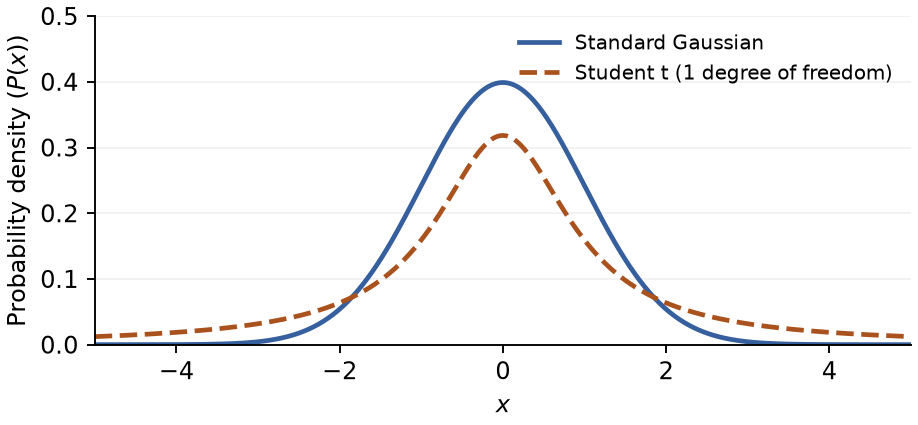

We normalise the weights across pairs to obtain $q_{ij}$:

$$
q_{ij}=
\frac{(1+\lVert y_i-y_j\rVert^2)^{-1}}
{\sum_{k\ne l}(1+\lVert y_k-y_l\rVert^2)^{-1}}
\quad (i\ne j).
$$

**Choosing the positions**

The feature probabilities $P=(p_{ij})$ are fixed. The plot probabilities $Q=(q_{ij})$ change whenever we move the points. We compare the two sets of probabilities using the Kullback–Leibler (KL) divergence:

$$
C=\mathrm{KL}(P\|Q)
=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

We move each point $y_i$ in the direction that decreases $C$ using gradient descent:

$$
\frac{\partial C}{\partial y_i}
=4\sum_{j\ne i}(p_{ij}-q_{ij})(y_i-y_j)
(1+\lVert y_i-y_j\rVert^2)^{-1},
\qquad
y_i\leftarrow y_i-\eta\,\frac{\partial C}{\partial y_i},
$$

where $\eta>0$ is the learning rate. If $p_{ij}>q_{ij}$, the pair is more similar in feature space than its current positions suggest, so its contribution to the update pulls the points together. If $q_{ij}>p_{ij}$, the update from that pair pushes them apart.

The provided helper plots 50 images from each of the first 10 classes. Colours indicate class labels, but those labels do not influence where t-SNE places the points.


In [14]:
def plot_tsne_with_legend(X, y, class_names, num_classes=10, title="t-SNE of HOG features"):
    """
    Run t-SNE on a subset of features and plot with class name legend.
    """
    # Subsample to make t-SNE faster and clearer
    num_per_class = 50
    selected_idx = []

    for cls in range(num_classes):
        idx = np.where(y == cls)[0][:num_per_class]
        selected_idx.extend(idx)

    X_sub = X[selected_idx]
    y_sub = y[selected_idx]

    print("Running t-SNE...")
    tsne = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto")
    X_embedded = tsne.fit_transform(X_sub)

    # Plot
    plt.figure(figsize=(10, 6))
    for cls in range(num_classes):
        idx = y_sub == cls
        plt.scatter(X_embedded[idx, 0], X_embedded[idx, 1], s=12, label=class_names[cls])

    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.legend(markerscale=1.5, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    plt.show()

Running t-SNE...


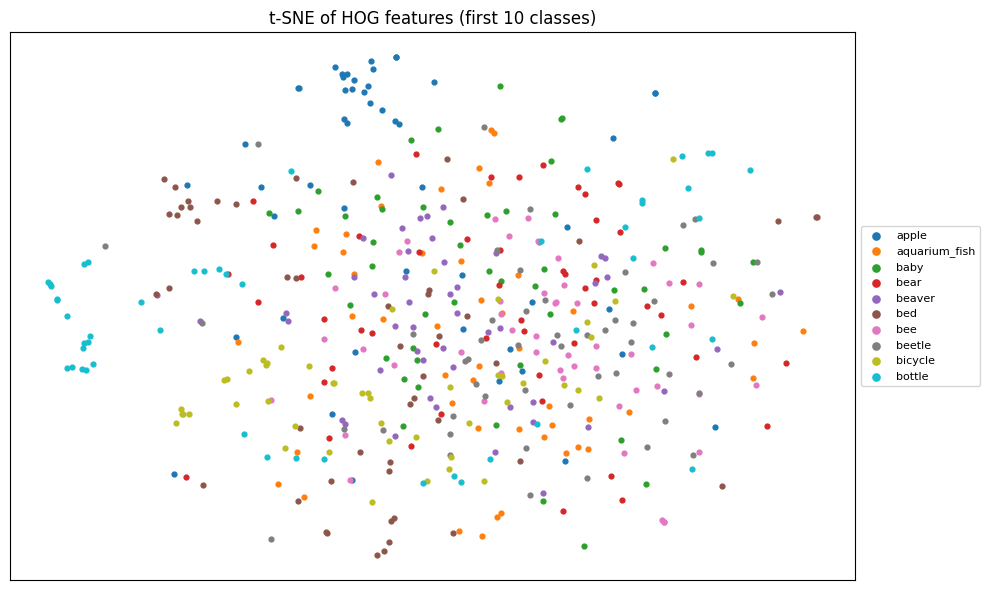

In [15]:
# Plot the HOG features
plot_tsne_with_legend(
    X_test_hog,
    y_test,
    class_names,
    num_classes=10,
    title="t-SNE of HOG features (first 10 classes)",
)

**Question:**

How can we interpret the t-SNE visualisations?


Class labels should be clustered together if the model is good enough. We could see here that the clusters are quite messy and mixed together.  

### 2. CNN for visual representation learning and downstream applications

We have previously introduced Convolutional Neural Networks (CNNs) in the lectures and experimented with them in earlier lab sessions. 
In this section, we will build a simple CNN from scratch and apply it to visual representation learning and classification on CIFAR-100.

We apply ReLU to the output of `fc1` and use the resulting **256 activations** as the image's feature vector. This is the representation that the final layer, `fc2`, uses to produce the 100 class scores. During training, the network learns these features through the classification objective, unlike HOG, whose features are handcrafted.

To inspect the learned representations later, we need the CNN to additionally return this feature vector alongside its output.


> **Task 3**: Modify `forward` so that it returns both the class scores and the 256-dimensional feature vector.


In [16]:
class CNN(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # [B, 32, 16, 16]
        x = self.pool(F.relu(self.conv2(x)))  # [B, 64, 8, 8]
        x = self.pool(F.relu(self.conv3(x)))  # [B, 128, 4, 4]
        x = x.view(x.size(0), -1)  # Flatten
        # > YOUR CODE HERE: retain the 256-dimensional feature vector
        features = self.fc1(x)
        logits = self.fc2(features)
        # > YOUR CODE HERE: return the features alongside the logits
        return features, logits 

We train the CNN for 15 epochs using cross-entropy loss and Adam. The training and evaluation code is provided below.


In [17]:
# Instantiate model, loss function, and optimiser

model = CNN(num_classes=100).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(dataloader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs, _ = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    avg_loss = running_loss / total
    acc = correct / total
    return avg_loss, acc


def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs, _ = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    acc = correct / total
    return avg_loss, acc

Epoch 1/15


Train Acc: 0.0244 | Test Acc: 0.0562
Epoch 2/15


Train Acc: 0.0877 | Test Acc: 0.1210
Epoch 3/15


Train Acc: 0.1523 | Test Acc: 0.1650
Epoch 4/15


Train Acc: 0.2125 | Test Acc: 0.1944
Epoch 5/15


Train Acc: 0.2567 | Test Acc: 0.2340
Epoch 6/15


... (6 outputs left out)

Train Acc: 0.5904 | Test Acc: 0.2626
Epoch 13/15


Train Acc: 0.6390 | Test Acc: 0.2632
Epoch 14/15


Train Acc: 0.7010 | Test Acc: 0.2594
Epoch 15/15


Train Acc: 0.7460 | Test Acc: 0.2628


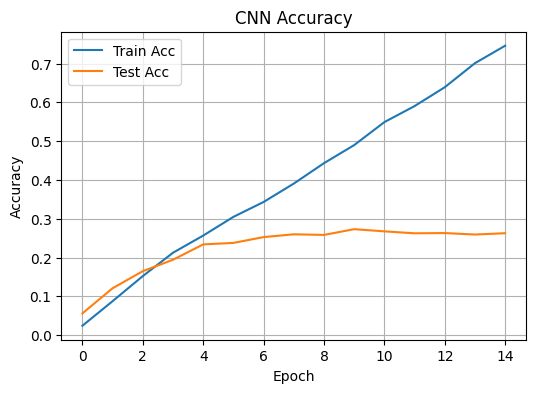

In [18]:
num_epochs = 15
train_losses, train_accs = [], []
test_losses, test_accs = [], []

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}/{num_epochs}")

    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(f"Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

# Plot accuracy curve
plt.figure(figsize=(6, 4))
plt.plot(train_accs, label="Train Acc")
plt.plot(test_accs, label="Test Acc")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

We save the trained CNN so that we can reload it for the at-home bonus.


In [19]:
# Save the trained weights
torch.save(
    {name: value.detach().cpu() for name, value in model.state_dict().items()},
    "cnn_cifar100.pt",
)

We now extract the trained CNN's representations for 50 test images from each of the first 10 classes and visualise them with t-SNE.

> **Task 4**: Complete `extract_cnn_features` to retrieve the feature vectors and append each selected vector to `features` as a NumPy array. The sample selection and plotting code are provided.


In [22]:
# Extract CNN features for t-SNE visualisation and analysis
def extract_cnn_features(model, dataloader, device, num_classes=10, samples_per_class=50):
    """
    Extract 256-dim features from CNN (fc1 layer).
    """
    model.eval()
    features = []
    labels = []
    class_counts = {cls: 0 for cls in range(num_classes)}

    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            # > YOUR CODE HERE: retrieve the feature vectors alongside the class scores
            _, batch_features = model(images)

            for i in range(len(images)):
                label = targets[i].item()
                if label < num_classes and class_counts[label] < samples_per_class:
                    # > YOUR CODE HERE: store the selected feature vector as a NumPy array
                    features.append(batch_features[i].cpu().numpy())
                    labels.append(label)
                    class_counts[label] += 1

            # stop early if all classes filled
            if all(count >= samples_per_class for count in class_counts.values()):
                break

    return np.array(features), np.array(labels)

Running t-SNE...


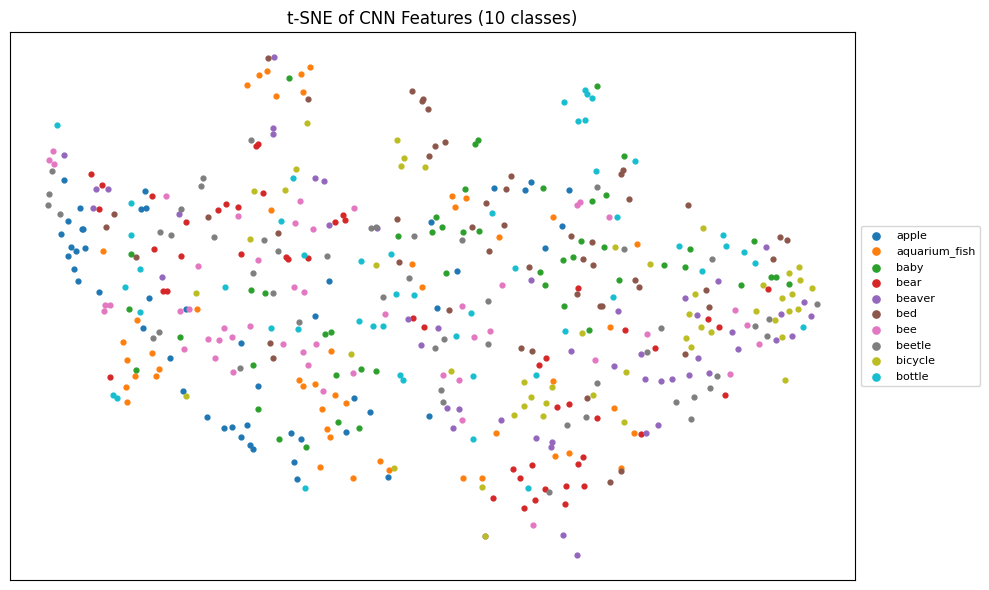

In [23]:
# Extract features (e.g. for first 10 classes)
X_cnn, y_cnn = extract_cnn_features(
    model, test_loader, device, num_classes=10, samples_per_class=50
)

# Plot using t-SNE with class legends
plot_tsne_with_legend(
    X_cnn, y_cnn, class_names, num_classes=10, title="t-SNE of CNN Features (10 classes)"
)

**Questions:**

- Why might the CNN classify CIFAR-100 images more accurately than logistic regression on HOG features?
- What differences do you notice between the t-SNE plots of HOG and CNN features?


1. The CNN classify images might be more accurately thna the logistic regression on HOG because firstly CNN is basically ideal for images and for CNN the filters and the classifier are trained together on the same loss, so the features are shaped to separate exactly these classes. Moreover, for logistic regression, the data need to be linearly seperable and clearly our data dont seem to be linearly seperable. 
2. t-SNE plots of CNN seems less dense and the cluster's situation is slightly improved but it is still not ideal because the clusters are still somehow mixed together.

### 3. Self-supervised deep visual representations with DINO-ViT

In this final section, we explore **self-supervised learning** with Vision Transformers (ViTs), focusing on **DINO** (Self-**Di**stillation with **No** Labels) - a state-of-the-art approach for learning visual representations **without any human-labelled data**.

#### Vision Transformers (ViT)

While CNNs extract local patterns using convolutional filters, ViTs ([Dosovitskiy et al., 2021](https://arxiv.org/pdf/2010.11929#page=3)) process images as sequences of patches using **self-attention** mechanisms, enabling them to capture **global semantic structure** more effectively.

A ViT adapts the transformer encoder we have already studied to images. The main change is how we construct the input sequence:

- **Patch embeddings:** We split the image into non-overlapping patches, flatten each patch, and apply the same learned linear projection to each one. Each resulting vector is a token, playing the role of a text-token embedding.
- **Position and image summary:** We prepend a learned **`[CLS]`** token and add learned positional embeddings, which identify the patch positions in the image.
- **Transformer encoder:** In each encoder layer, the `[CLS]` token attends to the patch tokens. We use its output vector from the final encoder layer to represent the whole image, just as we used the 256-dimensional feature vector from the CNN.

For the **ViT-S/16** used below (**S**mall Vision Transformer with **16x16-pixel patches**), each 224x224 RGB image gives $(224/16)^2=196$ patches. Each flattened patch contains $16\times16\times3=768$ values, projected to 384 dimensions. Adding `[CLS]` gives **197 tokens**, each with 384 values. `forward_features` therefore returns a tensor of shape `[B, 197, 384]` for a batch of size `B` and selecting `tokens[:, 0, :]` gives one 384-dimensional feature vector per image.

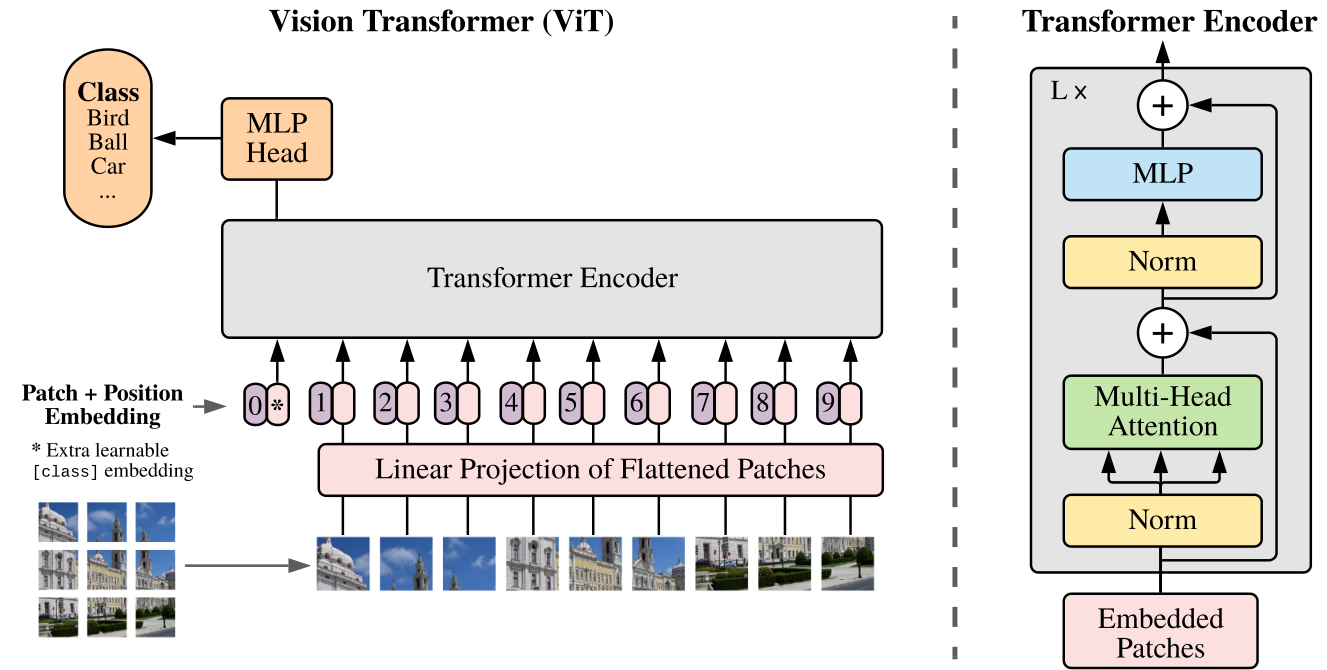

*Figure 1 from [Dosovitskiy et al. (2021)](https://arxiv.org/pdf/2010.11929#page=3). The `[class]` embedding in the figure is the `[CLS]` token described above. We extract its final encoder representation before the MLP classification head. The nine patches illustrate the construction; our model uses 196.*

<br>

#### DINO (Self-Distillation with No Labels)

**DINO ([Caron et al., 2021](https://arxiv.org/abs/2104.14294))** learns visual representations without class labels through **self-distillation**. During pretraining, we generate different views of each image using transformations such as cropping and changes in colour. Two networks, called the **student** and **teacher**, process these views.

Each network passes its ViT’s final `[CLS]` vector through a **projection head**. A softmax then turns the output into a probability vector. The student learns to match the teacher's output for another view of the same image. The teacher's probability vector provides the target for the student, so training requires no class labels.

The student's weights are updated by backpropagation. The teacher's weights follow an exponential moving average of the student's weights, providing targets that evolve gradually during training.

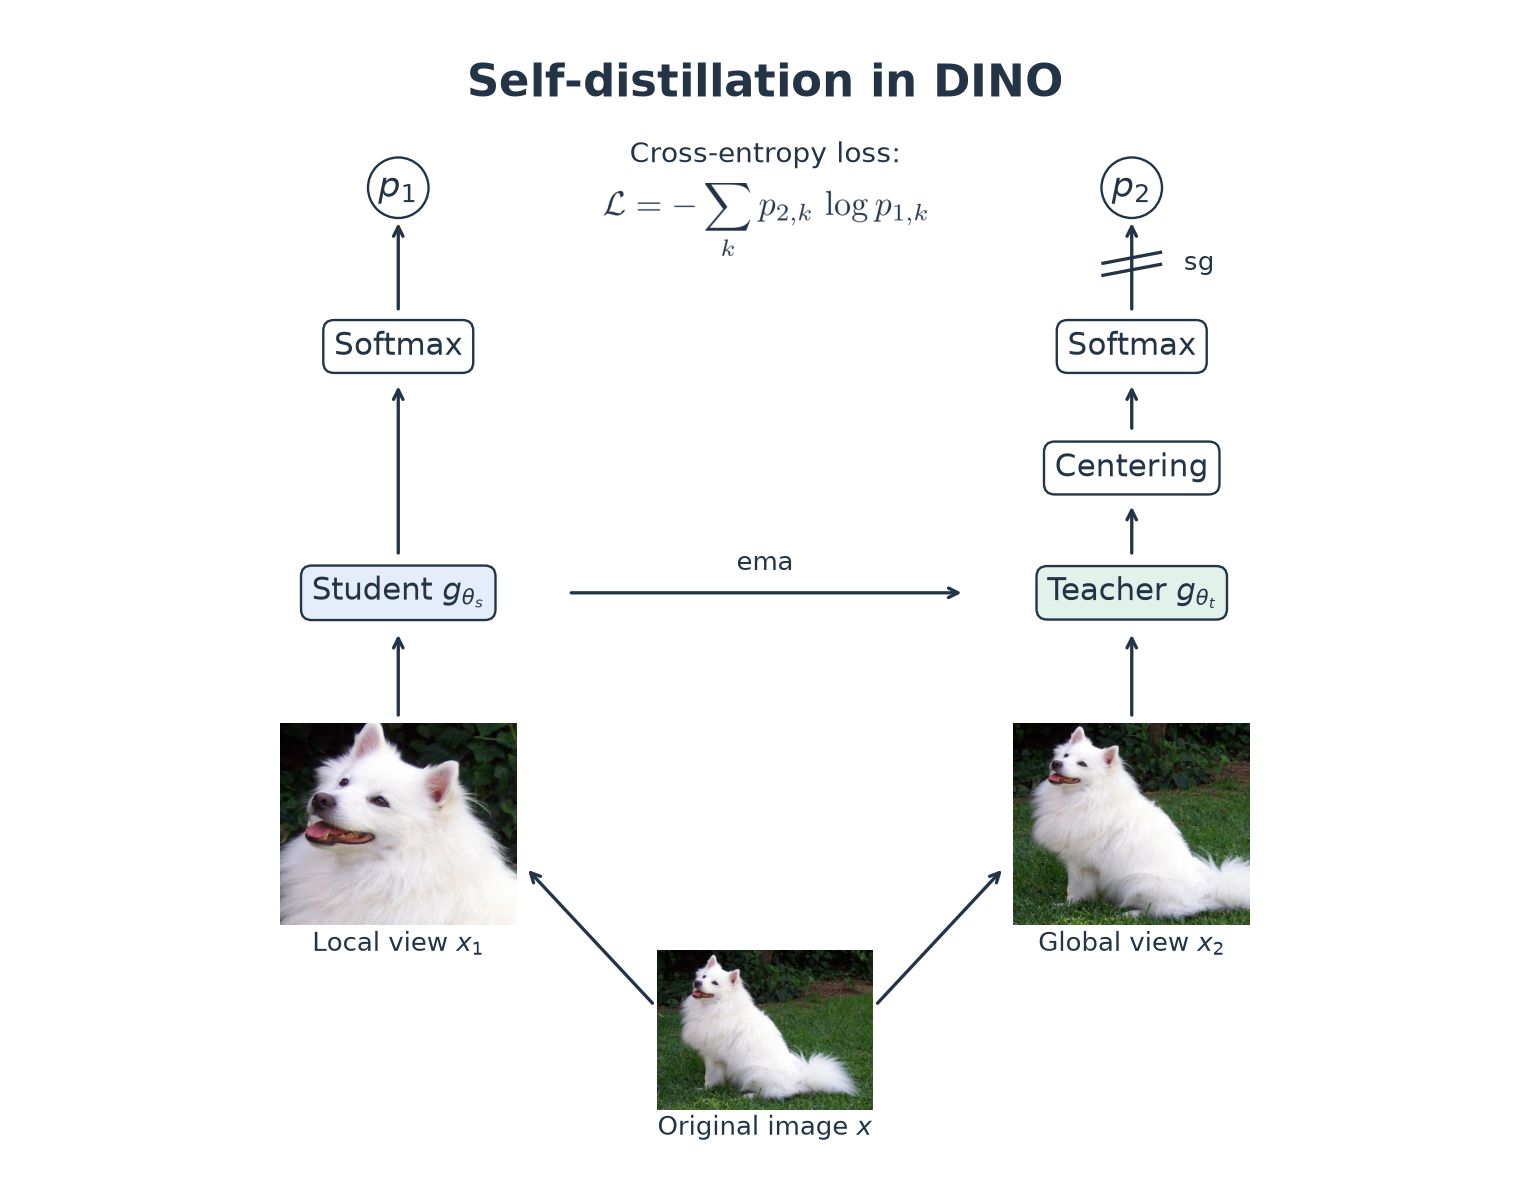

*The diagram shows one pairing of a local view $x_1$ with a global view $x_2$. The student predicts $p_1$ and the teacher provides the target $p_2$. Stop gradient (sg) holds the target fixed during backpropagation. The exponential moving average (ema) updates the teacher from the student’s weights. [Adapted from Figure 2 of Caron et al. (2021)](https://arxiv.org/html/2104.14294v2#S1.F2). [Example photograph from PyTorch Hub](https://github.com/pytorch/hub/blob/master/images/dog.jpg).*

<br>

This encourages the representation to capture information shared across different views of an image. The resulting features can be useful for classification, retrieval, or clustering, even though pretraining does not use object-category labels.

We will load a ViT-S/16 already [pretrained with DINO on ImageNet-1k](https://huggingface.co/timm/vit_small_patch16_224.dino#model-details) and keep its weights fixed while extracting CIFAR-100 features. For each image, we use the ViT's final `[CLS]` representation, leaving out the projection head used during pretraining.

In this section, we will:
- Extract visual features from a pretrained DINO-ViT model.
- Use these features for linear classification (logistic regression).
- Visualise the representation structure using t-SNE.

Here, **"without labels" refers to DINO pretraining**. The logistic regression classifier is trained using CIFAR-100 training labels, while the ViT remains frozen.

In [24]:
# Load pretrained DINO ViT model from timm
model_dino = timm.create_model("vit_small_patch16_224.dino", pretrained=True).to(device)
model_dino.eval()

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.7MB            

model.safetensors: downloading bytes:           |  0.00B            

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

In [25]:
# Use the pretrained model's evaluation preprocessing:
# bicubic resizing, a centre crop to 224x224, and ImageNet normalisation
data_config = timm.data.resolve_model_data_config(model_dino)
vit_transform = timm.data.create_transform(**data_config, is_training=False)

# Reuse the same splits and image order with the ViT transform
cifar_train_vit = CIFAR100Subset(train_images, train_labels, vit_transform)
cifar_test_vit = CIFAR100Subset(test_images, test_labels, vit_transform)

# Create dataloaders
cifar_train_vit_loader = DataLoader(cifar_train_vit, batch_size=64, shuffle=False)
cifar_test_vit_loader = DataLoader(cifar_test_vit, batch_size=64, shuffle=False)

The helper below extracts one feature vector per image in the loader. We use it to extract features for 50 test images from each of the first 10 classes and visualise them with t-SNE.

> **Task 5**: Complete `extract_dino_features`: use `model.forward_features` to obtain the output tokens, then select the final `[CLS]` representation for each image. Recall that `[CLS]` is the first token in the sequence (index 0). The resulting batch of feature vectors should have shape `[B, 384]`.


In [27]:
def extract_dino_features(model, dataloader, device=device):
    model.to(device)
    model.eval()

    features = []
    labels = []

    with torch.no_grad():
        for images, targets in tqdm(dataloader, desc="Extracting DINO features"):
            images = images.to(device)

            # > YOUR CODE HERE: obtain the output tokens and select the CLS representation
            tokens = model.forward_features(images)  # [B, 197, 384]
            cls = tokens[:, 0]  # [B, 384]

            features.append(cls.cpu().numpy())
            labels.append(targets.numpy())

    features = np.concatenate(features, axis=0)  # [N, 384]
    labels = np.concatenate(labels, axis=0)  # [N]
    return features, labels

Extracting DINO features: 100%|██████████| 8/8 [00:04<00:00,  1.64it/s]


Running t-SNE...


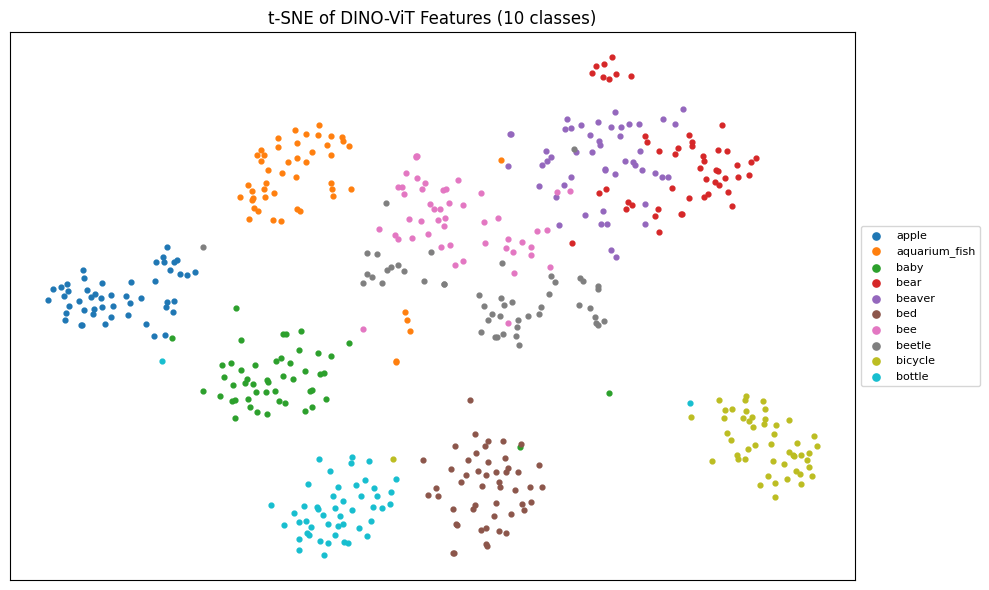

In [28]:
# Extract features for the 50 test images in each of the first 10 classes
plot_indices = np.flatnonzero(test_labels < 10)
plot_loader = DataLoader(
    torch.utils.data.Subset(cifar_test_vit, plot_indices.tolist()), batch_size=64
)
X_dino, y_dino = extract_dino_features(model_dino, plot_loader, device=device)

plot_tsne_with_legend(
    X_dino, y_dino, class_names, num_classes=10, title="t-SNE of DINO-ViT Features (10 classes)"
)

#### Classification with DINO features

We now train Logistic Regression on the DINO features and compare its classification accuracy with the earlier methods. To save computation, we load the provided features for the full training and test sets.



In [29]:
with np.load("dino_features_cifar100_subset.npz", allow_pickle=False) as features:
    X_train_dino = features["X_train_dino"]
    y_train_dino = features["y_train_dino"]
    X_test_dino = features["X_test_dino"]
    y_test_dino = features["y_test_dino"]

print("check X_train_dino and X_test_dino:", np.shape(X_train_dino), np.shape(X_test_dino))

check X_train_dino and X_test_dino: (10000, 384) (5000, 384)


> **Task 6**: Fit Logistic Regression on the provided DINO training features, predict the test labels, and compute the classification accuracy. Compare the result with HOG and the CNN.


In [30]:
# Train a Logistic Regression model on DINO features
print("Training Logistic Regression on DINO features...")
clf_lr = LogisticRegression(max_iter=300, solver="lbfgs", verbose=1)

# > YOUR CODE HERE: fit the classifier
clf_lr.fit(X_train_dino, y_train_dino)

# Evaluate on test set
# > YOUR CODE HERE: predict the test labels and compute accuracy
y_pred_lr = clf_lr.predict(X_test_dino)
acc_dino = accuracy_score(y_test_dino, y_pred_lr)

print(f"Logistic Regression Accuracy on CIFAR-100 (DINO): {acc_dino:.4f}")

Training Logistic Regression on DINO features...
Logistic Regression Accuracy on CIFAR-100 (DINO): 0.7606


In [31]:
print("Test accuracy")
print(f"HOG + Logistic Regression:  {acc_hog:.1%}")
print(f"CNN:                        {test_accs[-1]:.1%}")
print(f"DINO + Logistic Regression: {acc_dino:.1%}")

Test accuracy
HOG + Logistic Regression:  14.1%
CNN:                        26.3%
DINO + Logistic Regression: 76.1%


### 4. Open Problems

While deep visual representations have led to remarkable success across many computer vision tasks, there remain several open and fundamental challenges:

#### Long-Tail Distributions
- Real-world data is often highly imbalanced, where many "tail" classes have very few examples.
- Most methods struggle to learn good representations for rare classes, which can be critical in domains like medical imaging or wildlife monitoring.

#### Distribution Shift
- Models trained on one dataset (e.g., CIFAR-100) often fail to generalise to different data domains or environments.
- Robust representation learning under domain shift remains an active area of research.

#### Interpretability
- What exactly is encoded in the representation? Which part of the image contributes most? Understanding and explaining the learned features is still an open problem.

#### Bias and Fairness
- Visual representations can carry or amplify societal and dataset biases (e.g., skin tone, gender, geography).
- This can lead to unfair downstream decisions in sensitive applications such as facial recognition or hiring systems.

### 5. Bonus: Image Retrieval (optional, at home)

Visual representations can also support **image retrieval**: given a query image, we search a gallery for images with similar feature vectors. In this bonus, we compare the neighbours retrieved using HOG, CNN, and DINO features using cosine similarity.

We use the same gallery and queries for all three methods: **50 training images per class** form a gallery of 5,000 images, and **five test images per class** give 500 queries. Queries and gallery images come from separate dataset splits. The provided code selects the images, reuses the HOG and DINO features computed above, and reloads the saved CNN to extract its features. No further model training is needed.


In [32]:
from torch.utils.data import Subset

rng = np.random.default_rng(42)
train_targets = np.asarray(train_dataset.targets)
test_targets = np.asarray(test_dataset.targets)
num_classes = len(class_names)
gallery_per_class = 50
queries_per_class = 5

gallery_indices = np.sort(
    np.concatenate(
        [
            rng.choice(np.flatnonzero(train_targets == cls), gallery_per_class, replace=False)
            for cls in range(num_classes)
        ]
    )
)
query_indices = np.sort(
    np.concatenate(
        [
            rng.choice(np.flatnonzero(test_targets == cls), queries_per_class, replace=False)
            for cls in range(num_classes)
        ]
    )
)
gallery_labels = train_targets[gallery_indices]
query_labels = test_targets[query_indices]

# Keep the selected image order identical for all representations
gallery_loader = DataLoader(
    Subset(train_dataset, gallery_indices.tolist()), batch_size=128, shuffle=False
)
query_loader = DataLoader(
    Subset(test_dataset, query_indices.tolist()), batch_size=128, shuffle=False
)

retrieval_cnn = CNN(num_classes=num_classes).to(device)
retrieval_cnn.load_state_dict(torch.load("cnn_cifar100.pt", map_location=device, weights_only=True))
X_gallery_cnn, _ = extract_cnn_features(
    retrieval_cnn,
    gallery_loader,
    device,
    num_classes=num_classes,
    samples_per_class=gallery_per_class,
)
X_query_cnn, _ = extract_cnn_features(
    retrieval_cnn,
    query_loader,
    device,
    num_classes=num_classes,
    samples_per_class=queries_per_class,
)

# Each pair contains query features followed by gallery features
retrieval_features = {
    "HOG": (X_test_hog[query_indices], X_train_hog[gallery_indices]),
    "CNN": (X_query_cnn, X_gallery_cnn),
    "DINO": (X_test_dino[query_indices], X_train_dino[gallery_indices]),
}
print(f"Gallery: {len(gallery_indices)} images | Queries: {len(query_indices)} images")

Gallery: 5000 images | Queries: 500 images


> **Bonus task 1**: Complete `retrieve_neighbours` to compute the similarities between query and gallery features with `cosine_similarity` and return the gallery indices of the `k` most similar images for each query, ordered from most to least similar.


In [34]:
def retrieve_neighbours(query_features, gallery_features, k=5):
    # > YOUR CODE HERE: rank the gallery images by cosine similarity for each query
    similarities = cosine_similarity(query_features, gallery_features)
    neighbour_indices = np.argsort(-similarities, axis=1)[:, :k] 
    return neighbour_indices

We evaluate retrieval using **precision@5**: the proportion of the five retrieved images that share the query's class, averaged over all queries. Labels are used for evaluation; the ranking uses only the feature vectors.

> **Bonus task 2**: Complete `precision_at_k` to compute the average proportion of neighbours sharing the query's class. Use the provided code to compare the three representations and inspect some queries.


In [35]:
def precision_at_k(neighbour_indices, query_labels, gallery_labels):
    # > YOUR CODE HERE: average the proportion of same-class neighbours over all queries
    neighbour_labels = gallery_labels[neighbour_indices]
    same_class = neighbour_labels == query_labels[:, None]       
    return same_class.mean()

In [36]:
retrieved_neighbours = {}
for name, (query_features, gallery_features) in retrieval_features.items():
    neighbours = retrieve_neighbours(query_features, gallery_features, k=5)
    retrieved_neighbours[name] = neighbours
    score = precision_at_k(neighbours, query_labels, gallery_labels)
    print(f"{name}: precision@5 = {score:.1%}")

HOG: precision@5 = 7.2%
CNN: precision@5 = 11.5%
DINO: precision@5 = 53.9%


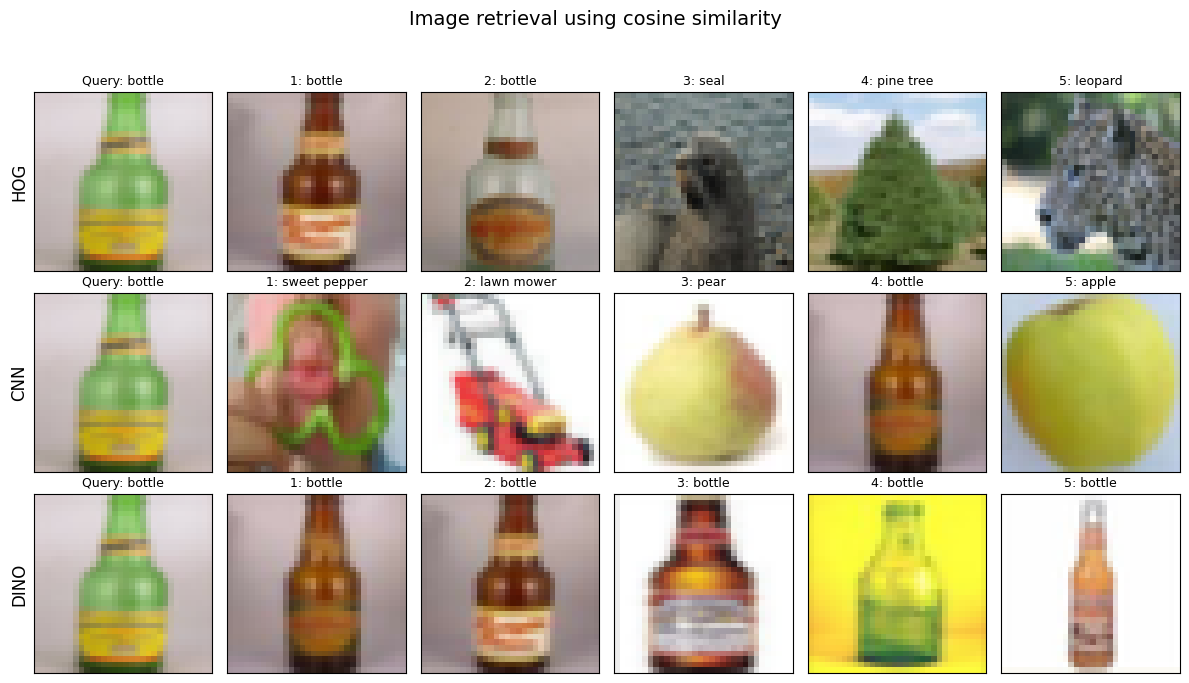

In [37]:
def plot_retrieval(query_position, retrieved_neighbours):
    fig, axes = plt.subplots(len(retrieved_neighbours), 6, figsize=(12, 7), squeeze=False)
    query_image = test_dataset.data[query_indices[query_position]]
    query_class = class_names[query_labels[query_position]].replace("_", " ")

    for row, (name, neighbours) in enumerate(retrieved_neighbours.items()):
        axes[row, 0].imshow(query_image)
        axes[row, 0].set_title(f"Query: {query_class}", fontsize=9, wrap=True)
        axes[row, 0].set_ylabel(name, fontsize=12)
        for rank, gallery_position in enumerate(neighbours[query_position]):
            image_index = gallery_indices[gallery_position]
            ax = axes[row, rank + 1]
            ax.imshow(train_dataset.data[image_index])
            label = class_names[gallery_labels[gallery_position]].replace("_", " ")
            ax.set_title(f"{rank + 1}: {label}", fontsize=9, wrap=True)
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])

    fig.suptitle("Image retrieval using cosine similarity", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()


# Show a bottle query. Change this position to inspect other queries (0 to 499).
plot_retrieval(query_position=328, retrieved_neighbours=retrieved_neighbours)

**Questions:**

- What kinds of visual similarity do the different representations favour?
- Can an image with a different class label still be a useful visual match? What does this imply about precision@5?


`Answer:` 

1. 
- For HOG: the first two bottles have the same background's color as the query. The seal, pine tree and the leopad have nothing in commun with the bottle, not even the color background. The only visual similarity seems to be that they are all the centered object in the image, with no other objects detected. 
- For CNN: only one answer is correct. The overall similarity could be the colors green and yellow because all these results have the overall color of greenish/yellow.  The background is similar for all the results except the sweet pepper. 
- For DINO: the similarity has to be the shape of the bottle. The background and the colors in the images do not play a role here. 

Precision@5 classifies something as the final result only if its class label equals the query’s label, so it measures semantic category agreement and nothing else.

2. A different label can still be a useful visual match. The pear and apple, or even a part of that sweet-pepper share the query’s yellow-green colour and smooth rounded form. For a specific task that might require searching for colour or shape, this could be useful.